# Lab 03: acquire small scientific inputs and explain failures

Automated Workflows in Satellite Image Processing · v1.0 · 15 October 2026

Lab 02 discovered catalogue items and stored one preview. This lab acquires the red
and near-infrared bands needed for NDVI, but stores only a small area of interest.
You design the new database tables completely and then use the resulting archive
to investigate failures.

Use this notebook for predictions, SQL inspection and explanations. Edit
`student_schema.sql` in your editor. Run acquisition and failure cases in a terminal.
The supplied Python is working code, not a new function-repair exercise.

Deliverables: your full schema SQL, your diagnostic SQL, this notebook with evidence
and explanations, and a small final JSON report. Core work: approximately two hours.


## 1. Setup and continuity

Read README.md for installation. From a terminal in this folder, install Rasterio,
NumPy, Matplotlib and Jupyter into your existing environment if needed:

```bash
conda install -c conda-forge "rasterio>=1.4,<2" numpy matplotlib jupyterlab ipykernel
```

We preserve Lab 02's streams, scenes, downloads, runs and stream_scenes tables. You
can copy your database with --from-lab2 on the first init; README.md gives the command.
The default path creates a separate Lab 03 archive and uses captured actual Lab 01
metadata. The original Lab 02 database is never edited by the copy operation.

The fixed example is from June 2025. It is chosen for reproducibility, not presented
as the newest acquisition. Live acquire commands always read remote COG data;
packaged real subsets are used only by offline checks.


In [ ]:
from pathlib import Path
import json
import sqlite3
import subprocess
import sys

PROJECT = Path.cwd().resolve()
assert (PROJECT / 'lab03_cli.py').is_file(), 'Set PROJECT to the extracted lab folder'

def run_checks():
    result = subprocess.run([sys.executable, str(PROJECT / 'check_lab03.py')], cwd=PROJECT, capture_output=True, text=True)
    print(result.stdout)
    if result.stderr:
        print(result.stderr)
    print('Exit code:', result.returncode)
    return result.returncode

print('Project:', PROJECT)


### Relationships and cardinality

| Parent → child | Cardinality | Answer |
|---|---|---|
| scenes → assets | 1 : N | Yes: one scene has a red and a nir asset, and each can have several metadata revisions. |
| assets → subset_requests | 1 : N | Yes: the same band can be stored for two AOIs (default and alternate, 2 requests per asset). |
| subset_requests → download_attempts | 1 : N | Yes: a request can fail and later succeed, and each try is its own row (e.g. nir in case A). |
| runs → download_attempts | 1 : N | Yes: one run attempts both bands (and verification). |
| download_attempts → artifacts | 1 : 0..1 creator | An artifact has exactly one creating attempt (the first to register those bytes); later attempts can only refer to it. |
| artifacts → artifact_locations | 1 : N | A file can disappear (`missing`/`corrupt`) while the artifact identity (hash, size, request) stays. |

**Current state vs. history.** Current state: `subset_requests.status` and `latest_artifact_id`, and `artifact_locations.status` and `checked_at`; these are updated in place. History: `download_attempts` (append-only, one row per try), `artifacts` (immutable identity of stored bytes) and `runs`.

**Why `run_id` and `subset_id` must not be unique in `download_attempts`.** `UNIQUE(subset_id)` would allow only one attempt per request, so a retry after a failure could not be recorded without overwriting the failed row, which would destroy the history we rely on in recovery. `UNIQUE(run_id)` would allow only one attempt per run, but one run attempts both bands (and verification adds attempts).

## 2. Design five complete tables (45–60 minutes)

Read SCHEMA_CONTRACT.md. Write every CREATE TABLE statement yourself in
student_schema.sql. The file initially contains only comments. Required column
names let the supplied service use your schema, but there are no partial table
statements to complete.

Before writing SQL, sketch these relationships and explain the expected cardinality:

| Parent | Child | Question |
|---|---|---|
| scenes | assets | Can one scene have more than one band or metadata revision? |
| assets | subset_requests | Can the same band be stored for two AOIs? |
| subset_requests | download_attempts | Can a request fail and later succeed? |
| runs | download_attempts | Can one invocation attempt more than one band? |
| download_attempts | artifacts | Which attempt first registered these exact bytes? |
| artifacts | artifact_locations | Can a stored file disappear without erasing the artifact's identity? |

Also record each request's latest artifact and each attempt's result artifact.
Those artifacts must belong to the same request, not simply be any existing ID.
The contract explains the composite references needed for that condition.

Which facts belong to current state, and which must remain as history? Do not
make run_id or subset_id unique in the attempts table. Predict what that would
prevent during recovery.


In [ ]:
run_checks()


Write your schema explanation here. Identify two uniqueness constraints and two
foreign key constraints, and give a concrete bad record each would reject. Explain
why an asset+band identity alone is insufficient when the AOI changes.

### Schema explanation

**Two uniqueness constraints**

1. `assets`: `UNIQUE (collection, item_id, asset_key, metadata_sha256)`.
   A logical asset revision is one band of one scene with one version of the provider metadata. Registering the same metadata twice must not create two revisions.
   *Rejected record:* a second `assets` row with a new `asset_id` (`'duplicate'`) but the same collection, item, `asset_key = 'red'` and the same `metadata_sha256` as an existing row. Without the constraint the archive would contain two "different" assets for identical source data, and requests could attach to either one.

2. `subset_requests`: `UNIQUE (asset_id, aoi_key, recipe_version)`.
   A request is defined by the source asset, the AOI and the extraction recipe.
   *Rejected record:* a second request with a new `subset_id` for the same `asset_id`, `aoi_key` and `recipe_version`. Without it the same crop could be tracked twice, with two competing statuses and artifacts.

**Two foreign keys**

1. `assets (collection, item_id) → scenes (collection, item_id)`.
   *Rejected record:* an `assets` row for an `item_id` that is not in `scenes` (an orphan source asset). A band must belong to a catalogued scene, otherwise its lineage cannot be traced to a catalogue search.

2. Composite `subset_requests (latest_artifact_id, subset_id) → artifacts (artifact_id, subset_id)`.
   *Rejected record:* setting `latest_artifact_id` of the alternate-AOI request to the id of the artifact produced for the default AOI. That artifact exists, but its `subset_id` is a different request, so the pair is not found in `artifacts` and the update fails. A plain foreign key on `artifact_id` alone would accept it. (The same pairing protects `download_attempts.artifact_id` and `artifacts.created_by_attempt_id`.)

**Why asset + band is not enough when the AOI changes**

The remote band file is the same for every AOI, but each AOI produces different stored bytes: a different window, shape, transform and mask, and therefore a different hash, artifact and file. If a request were identified only by asset and band, a second AOI would either be rejected as a duplicate of the first or overwrite its state, and one artifact could be wrongly used for both. The identity of what we store must include the AOI (via `aoi_key`) and the recipe, as in `UNIQUE (asset_id, aoi_key, recipe_version)`. This is what lets the default and the alternate AOI of the same red band exist side by side, each with its own request, artifact and file path.


## 3. Plan before storing scientific data (10 minutes)

Once checks pass, initialize the new archive and inspect the planned size:

```bash
python lab03_cli.py init --config config/krakow_aoi.json
```

```bash
python lab03_cli.py plan --config config/krakow_aoi.json
```

Open config/krakow_aoi.json. Distinguish discovery_bbox, which selects catalogue
candidates, from aoi_bbox, which limits the stored pixels. Both use west, south,
east, north in EPSG:4326. item_id pins one tile; the AOI must fit entirely inside it.

For each band, report source_shape, subset shape, pixel size, CRS, raw pixel bytes,
scale and offset. The supplied default should produce 227 rows by 219 columns at
10 m resolution, much smaller than the 10,980 by 10,980 source tile.



Use the alternative too_large_aoi.json configuration to investigate a budget failure:

```bash
python lab03_cli.py plan --config config/too_large_aoi.json
```

That command is expected to fail before remote raster data is read. Explain why a
local disk limit and an HTTP transfer limit are different controls. Reading a COG
window fetches whole source blocks; network bytes may exceed stored file bytes.


### Plan results (`krakow_aoi.json`)

Scene: `S2C_34UDA_20250605_0_L2A` · AOI (W, S, E, N, EPSG:4326): `[19.91, 50.04, 19.94, 50.06]`

| Band | source_shape (rows × cols) | subset shape (rows × cols) | pixel size | CRS | raw_pixel_bytes | scale | offset |
|---|---|---|---|---|---|---|---|
| red (B04) | 10980 × 10980 | 227 × 219 | 10 m | EPSG:32634 | 99,426 | 0.0001 | −0.1 |
| nir (B08) | 10980 × 10980 | 227 × 219 | 10 m | EPSG:32634 | 99,426 | 0.0001 | −0.1 |

Total for the pair: 198,852 bytes of uncompressed pixel payload (219 × 227 pixels × 2 bytes per band).
The window is `[col_off, row_off, width, height] = [2198, 5416, 219, 227]`. The subset covers about 0.04% of the source tile (49,713 of about 120.6 million pixels). Both bands have identical CRS, transform, shape and window, so they are aligned and no resampling is needed.

The reflectance conversion is `reflectance = DN × 0.0001 − 0.1`. Rasterio does not apply scale and offset automatically, and the offset does not cancel in NDVI = (NIR − Red) / (NIR + Red), so it must be applied before computing NDVI.

### Budget failure (`too_large_aoi.json`)

`plan` failed with `ValueError: AOI window is empty or exceeds the pixel budget`. No raster data was read: the pixel window is computed only from catalogue metadata (the source grid transform, the tile shape and the AOI bounds), so the budget check can reject the request before any HTTP range request is made. In this configuration the window exceeds `max_pixels_per_band`. This is cheap and safe: nothing is downloaded or stored for a request that would be rejected anyway.

### Disk limit vs. HTTP transfer limit

These are two different controls on two different resources.

- **Local disk/storage limits** (`max_pixels_per_band`, `max_output_bytes_per_band`, `workspace_budget_bytes`) bound what is kept: the size of the cropped window, the size of each output GeoTIFF and the total size of the data folder. They protect disk space and memory.
- **The HTTP transfer limit** (`range_byte_budget_per_band`) bounds how many response-body bytes are received from the remote server while reading the window. It protects the network and prevents a crop from silently turning into a full-tile download.

They are not the same number. A COG is read in whole internal blocks, plus header/metadata requests, so the bytes received over HTTP can be larger than the bytes of the stored cropped file, which is also compressed and masked. A small output can therefore still exceed the transfer budget, and a request can satisfy the disk limit but fail the network limit.

## 4. Acquire and repeat (10 minutes plus network time)

```bash
python lab03_cli.py acquire --config config/krakow_aoi.json
```

```bash
python lab03_cli.py acquire --config config/krakow_aoi.json
```

```bash
python lab03_cli.py report --config config/krakow_aoi.json
```

The first run requests two real bands via byte ranges and stores two masked AOI
GeoTIFFs. The second checks their size, SHA-256 and raster metadata and records
reused attempts. Explain why reused is not another transfer and why it is still
worth recording.

Open state/catalogue.sqlite in DB Browser. Inspect the five original tables and
your five new tables. Existing preview downloads remain in downloads; scientific
cutout attempts are in download_attempts and link to subset_requests.


### Acquire results

| Band | HTTP status | Network bytes (HTTP body) | Saved GeoTIFF bytes | Raw pixel payload (plan) |
|---|---|---|---|---|
| red | 206 | 2,097,153 | 75,792 | 99,426 |
| nir | 206 | 2,097,153 | 76,138 | 99,426 |

Both first-run attempts ended `succeeded` at stage `complete`, with HTTP 206 (partial content), so only byte ranges were read, never the full tile. About 2 MiB per band came over the network, roughly 27.5–27.7 times the size of the saved file. COG data is read in whole internal blocks plus header and probe requests, not just the cropped pixels. The stored file is also smaller than the raw pixel payload (about 76%) because the GeoTIFF is deflate-compressed. 2,097,153 is consistent with eight 256 KiB blocks plus a one-byte size probe. This is far below the 12 MiB per-band transfer budget.

### Second run: `reused`

The second `acquire` produced two attempts with status `reused`, stage `cache_verify`, `network_bytes = 0` and no HTTP status. No transfer happened: the program checked that the recorded file exists, has the recorded size and SHA-256, and passes raster validation (grid, CRS, nodata, scale/offset, AOI mask), and that the current plan matches the cached plan. The artifact identity stayed the same and the location's `checked_at` was refreshed.

It is still worth recording because the history shows that the artifact was verified, when, and by which run. If a file is later lost or corrupted, the history lets me distinguish "the file was intact at run N" from "the file was never checked", and the failed verification is a separate attempt that does not rewrite the earlier successful one.

### One worked SQL join

Run this in Execute SQL. It follows an attempt to its run, AOI request and source
band. Use it as a starting point for your own diagnostic queries.

```sql
SELECT r.run_id, r.command, a.item_id, a.asset_key,
       s.aoi_key, d.status, d.stage, d.network_bytes,
       d.http_status, d.error_code, d.error_message
FROM download_attempts AS d
JOIN runs AS r ON r.run_id = d.run_id
JOIN subset_requests AS s ON s.subset_id = d.subset_id
JOIN assets AS a ON a.asset_id = s.asset_id
ORDER BY d.started_at, d.attempt_id;
```

Write your own query to show the saved paths, file hashes and latest location
states. Compare HTTP bytes with file sizes. Do not sum bytes after joining a
one-to-many location table unless you account for the duplicated attempt rows.


In [1]:
import sqlite3
from pathlib import Path

DB = Path.cwd() / 'state' / 'catalogue.sqlite'
QUERY = """
SELECT a.asset_key, s.aoi_key, f.artifact_id, f.sha256, f.size_bytes,
       l.local_path, l.status AS location_status, l.checked_at,
       (SELECT SUM(d.network_bytes) FROM download_attempts d
         WHERE d.subset_id = s.subset_id AND d.status = 'succeeded') AS http_bytes
FROM subset_requests s
JOIN assets a ON a.asset_id = s.asset_id
JOIN artifacts f ON f.artifact_id = s.latest_artifact_id
JOIN artifact_locations l ON l.artifact_id = f.artifact_id
ORDER BY a.asset_key, l.checked_at DESC;
"""
with sqlite3.connect(f'{DB.as_uri()}?mode=ro', uri=True) as conn:
    conn.row_factory = sqlite3.Row
    for row in conn.execute(QUERY):
        print(dict(row))

{'asset_key': 'nir', 'aoi_key': '48e7066dc2510b10454cbc305c90ecb47f71c0966d733d6ab4ec2630c8745724', 'artifact_id': 'fca9fc0ea7e68ceff3015929352513dbcdd0d9a9d9e5d75cb90ca393bc502adb', 'sha256': '94733ceb5a90b44961485d021290543635df521a4c1da4d6fbb79ef7ec5f7d72', 'size_bytes': 76138, 'local_path': 'C:\\Users\\mzawa\\Desktop\\mgr - II sem\\Authomated_Workflows_Windows\\Automated_Workflows\\Labs\\Lab03\\data\\S2C_34UDA_20250605_0_L2A\\48e7066dc251\\nir-fca9fc0ea7e68cef.tif', 'location_status': 'available', 'checked_at': '2026-11-01T16:04:48.470342Z', 'http_bytes': 2097153}
{'asset_key': 'red', 'aoi_key': '48e7066dc2510b10454cbc305c90ecb47f71c0966d733d6ab4ec2630c8745724', 'artifact_id': '59d7497b6d0acac9cc3d487175e8d2cbd5d8612fbd1a58b9e37d8eb83d7c06e1', 'sha256': 'df429fb5eff330afe76e6dd0b7e749fba163e77dada3bdf6c6e18e430c601441', 'size_bytes': 75792, 'local_path': 'C:\\Users\\mzawa\\Desktop\\mgr - II sem\\Authomated_Workflows_Windows\\Automated_Workflows\\Labs\\Lab03\\data\\S2C_34UDA_2025060

In [ ]:
DB = PROJECT / 'state' / 'catalogue.sqlite'
if not DB.is_file():
    print('Write/check the schema and run init/acquire in the terminal first.')
else:
    with sqlite3.connect(f'{DB.as_uri()}?mode=ro', uri=True) as conn:
        names = {row[0] for row in conn.execute("SELECT name FROM sqlite_master WHERE type='table'")}
        if 'download_attempts' not in names:
            print('The five new tables have not been initialized yet.')
        else:
            conn.row_factory = sqlite3.Row
            rows = [dict(row) for row in conn.execute('SELECT run_id,status,stage,network_bytes,error_code FROM download_attempts ORDER BY rowid')]
            print(json.dumps(rows, indent=2))


### Paths, hashes and location state

The query returns one row per band. Each has a full SHA-256, a stored size (red 75,792 B, nir 76,138 B), a local path and location status `available`, with `checked_at` from the second run (the `reused` verification). HTTP bytes are summed in a correlated subquery over succeeded attempts only, so joining the one-to-many `artifact_locations` table cannot duplicate attempt rows and inflate the total. The 2,097,153 network bytes per band are about 27.5× the saved file size, because COG reads fetch whole blocks and the output is a small, compressed, masked crop.

Note: the database stores the path and the expected size/hash; only a filesystem check (done by the `cache_verify` attempt) can confirm the file is still there and unchanged.

## 5. Failure case A: one band succeeded, then the connection failed (20 minutes)

Predict the database and file states before running this:

```bash
python lab03_cli.py case --config config/krakow_aoi.json --name network
```

The command creates cases/network/config.json and its own database/data directory,
then deliberately interrupts the nir reader after actual range responses. A
failure exit code is expected. It does not damage the main archive. The connection
failure is controlled; the scene records and imagery are real.

Open cases/network/state/catalogue.sqlite. Before any recovery:

1. Write SQL to identify the failed run, failed band, failure stage and bytes received.
2. Show which band already has an artifact and which has none.
3. Explain why a failed run does not imply that every operation in it failed. How could an INNER JOIN to artifacts hide the failed attempt?
4. Explain why advancing a discovery watermark would not prove a band was stored.

Record evidence, then recover:

```bash
python lab03_cli.py acquire --config cases/network/config.json
```

Show that the red file was verified/reused, the nir operation was retried, and the
original failure remains in the attempts table. Do not overwrite the failed row
to make the history look successful. Finish with a small before/after table of
run, band, attempt status, stage and artifact identity.

### Case A prediction

[If written after running, say so here, e.g. "reconstructed from the code".] The case reads `red` normally, then interrupts the `nir` reader after real range responses. Expected: `red` attempt `succeeded`/`complete` with an artifact and file; `nir` attempt `failed` at `read_window`, `RANGE_READ_FAILED`, some bytes received but no artifact and no file (the temporary `.part.tif` is deleted by the error handler); `nir` request `failed`, `red` request `ready`; the run `failed`.

### Case A evidence (before recovery)

**1. Failed run, band, stage, bytes.** One attempt failed: `nir`, stage `read_window`, `RANGE_READ_FAILED` ("Controlled network interruption after actual range responses"), HTTP 206, 262,145 bytes received (consistent with one size-probe byte plus one 256 KiB block). The run has status `failed` with the same error.

**2. Which band has an artifact.** `red`: request `ready`, artifact of 75,792 bytes at an `available` location. `nir`: request `failed`, no artifact and no location. LEFT JOINs are needed to see the empty side. Only the `red` file is on disk.

**3. A failed run does not mean every operation failed.** The run is the invocation; the attempt is one operation. `red` finished and was stored before `nir` failed. Query 1 (all attempts) returns 2 rows, while the same query with an `INNER JOIN` to `artifacts` returns 1: the failed attempt has `artifact_id = NULL`, so nothing matches in `artifacts` and the row disappears. An analysis starting from artifacts would report no failure; starting from `download_attempts` with LEFT JOINs keeps it.

**4. Why advancing a watermark would not prove a band was stored.** `streams.watermark` (`2026-09-21T00:00:00Z`) records how far catalogue discovery has progressed, not whether a band was downloaded, verified and registered. That is shown only by `subset_requests`, `artifacts`, `artifact_locations` and the files.


In [2]:
import sqlite3
from pathlib import Path

CASE_DB = Path.cwd() / 'cases' / 'network' / 'state' / 'catalogue.sqlite'
assert CASE_DB.is_file(), 'Run: python lab03_cli.py case --config config/krakow_aoi.json --name network'

def show(title, sql):
    with sqlite3.connect(f'{CASE_DB.as_uri()}?mode=ro', uri=True) as conn:
        conn.row_factory = sqlite3.Row
        rows = [dict(r) for r in conn.execute(sql)]
    print(f'\n=== {title}  ({len(rows)} rows) ===')
    for r in rows:
        print(r)
    return rows

# A1: failed run, failed band, stage and bytes
a1 = show('A1 failed attempts', """
SELECT r.run_id, r.command, r.status AS run_status, r.error AS run_error,
       a.asset_key, d.attempt_id, d.status AS attempt_status, d.stage,
       d.network_bytes, d.http_status, d.error_code, d.error_message
FROM download_attempts d
JOIN runs r ON r.run_id = d.run_id
JOIN subset_requests s ON s.subset_id = d.subset_id
JOIN assets a ON a.asset_id = s.asset_id
WHERE d.status = 'failed'
ORDER BY d.started_at, d.attempt_id;""")

# A2: which band has an artifact, which has none
a2 = show('A2 artifact per band', """
SELECT a.asset_key, s.status AS request_status, s.latest_artifact_id,
       f.size_bytes, l.local_path, l.status AS location_status
FROM subset_requests s
JOIN assets a ON a.asset_id = s.asset_id
LEFT JOIN artifacts f ON f.artifact_id = s.latest_artifact_id
LEFT JOIN artifact_locations l ON l.artifact_id = f.artifact_id
ORDER BY a.asset_key;""")

# A3: all attempts vs. INNER JOIN to artifacts
a3_all = show('A3 query 1: all attempts (no join to artifacts)', """
SELECT a.asset_key, d.attempt_id, d.status, d.stage, d.artifact_id
FROM download_attempts d
JOIN subset_requests s ON s.subset_id = d.subset_id
JOIN assets a ON a.asset_id = s.asset_id
ORDER BY d.started_at;""")
a3_inner = show('A3 query 2: INNER JOIN artifacts', """
SELECT a.asset_key, d.attempt_id, d.status, d.stage, f.artifact_id
FROM download_attempts d
JOIN subset_requests s ON s.subset_id = d.subset_id
JOIN assets a ON a.asset_id = s.asset_id
JOIN artifacts f ON f.artifact_id = d.artifact_id
ORDER BY d.started_at;""")
print(f'\nA3 row counts: all attempts = {len(a3_all)}, with INNER JOIN = {len(a3_inner)}')

# A4: watermark vs. stored bands
show('A4a watermark', 'SELECT stream_key, watermark FROM streams;')
show('A4b request state', """
SELECT a.asset_key, s.status, s.latest_artifact_id IS NOT NULL AS has_artifact
FROM subset_requests s JOIN assets a ON a.asset_id = s.asset_id;""")


=== A1 failed attempts  (1 rows) ===
{'run_id': 'lab03-47125083-627c-4e79-850d-0e8a0c3a2cf1', 'command': 'acquire', 'run_status': 'failed', 'run_error': 'Controlled network interruption after actual range responses', 'asset_key': 'nir', 'attempt_id': 'attempt-677e8ed0-7286-4184-9c6c-5ba1ee7f049d', 'attempt_status': 'failed', 'stage': 'read_window', 'network_bytes': 262145, 'http_status': 206, 'error_code': 'RANGE_READ_FAILED', 'error_message': 'Controlled network interruption after actual range responses'}

=== A2 artifact per band  (2 rows) ===
{'asset_key': 'nir', 'request_status': 'failed', 'latest_artifact_id': None, 'size_bytes': None, 'local_path': None, 'location_status': None}
{'asset_key': 'red', 'request_status': 'ready', 'latest_artifact_id': '59d7497b6d0acac9cc3d487175e8d2cbd5d8612fbd1a58b9e37d8eb83d7c06e1', 'size_bytes': 75792, 'local_path': 'C:\\Users\\mzawa\\Desktop\\mgr - II sem\\Authomated_Workflows_Windows\\Automated_Workflows\\Labs\\Lab03\\cases\\network\\data\\S2C_

[{'asset_key': 'red', 'status': 'ready', 'has_artifact': 1},
 {'asset_key': 'nir', 'status': 'failed', 'has_artifact': 0}]

### Case A evidence (before recovery)

**1. Failed run, band, stage, bytes.** One attempt failed: `nir`, stage `read_window`, `RANGE_READ_FAILED` ("Controlled network interruption after actual range responses"), HTTP 206, 262,145 bytes received (consistent with one size-probe byte plus one 256 KiB block). The run has status `failed` with the same error.

**2. Which band has an artifact.** `red`: request `ready`, artifact of 75,792 bytes at an `available` location. `nir`: request `failed`, no artifact and no location. LEFT JOINs are needed to see the empty side. Only the `red` file is on disk.

**3. A failed run does not mean every operation failed.** The run is the invocation; the attempt is one operation. `red` finished and was stored before `nir` failed. Query 1 (all attempts) returns 2 rows, while the same query with an `INNER JOIN` to `artifacts` returns 1: the failed attempt has `artifact_id = NULL`, so nothing matches in `artifacts` and the row disappears. An analysis starting from artifacts would report no failure; starting from `download_attempts` with LEFT JOINs keeps it.

**4. Why advancing a watermark would not prove a band was stored.** `streams.watermark` (`2026-09-21T00:00:00Z`) records how far catalogue discovery has progressed, not whether a band was downloaded, verified and registered. That is shown only by `subset_requests`, `artifacts`, `artifact_locations` and the files.

In [3]:
from pathlib import Path
for p in sorted((Path.cwd() / 'cases' / 'network' / 'data').rglob('*')):
    if p.is_file(): print(p.name, p.stat().st_size)

red-59d7497b6d0acac9.tif 75792


In [4]:
a5 = show('A5 before/after (history)', """
SELECT r.run_id, r.command, r.status AS run_status, a.asset_key,
       d.status AS attempt_status, d.stage, d.error_code, d.artifact_id, d.started_at
FROM download_attempts d
JOIN runs r ON r.run_id = d.run_id
JOIN subset_requests s ON s.subset_id = d.subset_id
JOIN assets a ON a.asset_id = s.asset_id
ORDER BY d.started_at, d.attempt_id;""")


=== A5 before/after (history)  (4 rows) ===
{'run_id': 'lab03-47125083-627c-4e79-850d-0e8a0c3a2cf1', 'command': 'acquire', 'run_status': 'failed', 'asset_key': 'red', 'attempt_status': 'succeeded', 'stage': 'complete', 'error_code': None, 'artifact_id': '59d7497b6d0acac9cc3d487175e8d2cbd5d8612fbd1a58b9e37d8eb83d7c06e1', 'started_at': '2026-11-01T16:12:29.104864Z'}
{'run_id': 'lab03-47125083-627c-4e79-850d-0e8a0c3a2cf1', 'command': 'acquire', 'run_status': 'failed', 'asset_key': 'nir', 'attempt_status': 'failed', 'stage': 'read_window', 'error_code': 'RANGE_READ_FAILED', 'artifact_id': None, 'started_at': '2026-11-01T16:12:39.263895Z'}
{'run_id': 'lab03-07536b76-8eff-4a88-8b37-5c398860ac72', 'command': 'acquire', 'run_status': 'succeeded', 'asset_key': 'red', 'attempt_status': 'reused', 'stage': 'cache_verify', 'error_code': None, 'artifact_id': '59d7497b6d0acac9cc3d487175e8d2cbd5d8612fbd1a58b9e37d8eb83d7c06e1', 'started_at': '2026-11-01T16:15:25.089236Z'}
{'run_id': 'lab03-07536b76-8e

### Case A recovery

Recovery command: `python lab03_cli.py acquire --config cases/network/config.json`

| Phase | Run (status) | Band | Attempt status | Stage | Error code | Artifact |
|---|---|---|---|---|---|---|
| Before (run 1) | `lab03-47125083…` (failed) | red | succeeded | complete | – | `59d7497b…` |
| Before (run 1) | `lab03-47125083…` (failed) | nir | failed | read_window | RANGE_READ_FAILED | none |
| After (run 2) | `lab03-07536b76…` (succeeded) | red | reused | cache_verify | – | `59d7497b…` (same) |
| After (run 2) | `lab03-07536b76…` (succeeded) | nir | succeeded | complete | – | `fca9fc0e…` (new) |

The recovery run did only the work that was missing. For `red` it ran `cache_verify`: the recorded file was present with the recorded size, SHA-256 and raster metadata, so the existing artifact `59d7497b…` was reused and no data was transferred. For `nir` it started a new `read_window` attempt, which this time completed, registered a new artifact and ended `succeeded`. The second run therefore finished with status `succeeded`.

The original failure was not overwritten. The `nir` attempt from run 1 is still in `download_attempts` as `failed`, at stage `read_window` with error code `RANGE_READ_FAILED`, and the first run still has status `failed`. History is append-only: a new attempt is a new row, and the state tables (`subset_requests`, `artifact_locations`) are what change to reflect the present: `nir` is now `ready` with an artifact. If the failed row were rewritten as a success, it would be impossible to show that a network failure occurred, which band it affected, or how much was received before it (262,145 bytes).

### What the database guarantees and what needs other evidence

**Protected by constraints:** identity uniqueness (asset revision, request, artifact per request, one row per path); parentage (scene → asset → request → attempt → artifact → location); that a request's latest artifact, an attempt's artifact and an artifact's creating attempt belong to the same request (composite keys); allowed statuses; non-negative byte counts; `running` rows without a finish time and terminal rows with one; `ready` requests with an artifact and `succeeded`/`reused` attempts with an artifact; valid JSON.

**Requires checking bytes, the filesystem or raster metadata:** whether the file still exists (`FILE_MISSING`) and still has the recorded size and SHA-256 (`FILE_CORRUPT`); whether the raster still has the recorded CRS, grid, nodata, scale/offset and AOI mask; whether the remote server really returned partial content for the requested ranges; and whether a location row is current (it is only as fresh as the last verification). A foreign key can say that a path was recorded, not that a file is there.

## 6. Failure case B: recorded success, missing file (20 minutes)

Predict whether a foreign key can detect a missing disk file. Then run:

```bash
python lab03_cli.py case --config config/krakow_aoi.json --name missing
```

This creates an independent case, acquires real subsets, deletes only that case's
red file, and verifies the archive. A failure exit code is expected. Inspect
cases/missing/state/catalogue.sqlite before recovery.

Write diagnostic SQL and explain:

- Which historical attempt succeeded? Which later operation detected the loss?
- Which table describes the file's current availability, and which describes the
  bytes that previously existed?
- Why should the original successful attempt remain successful in the history?
- What can the database prove, and what required reading the filesystem?

Recover with the same configuration:

```bash
python lab03_cli.py acquire --config cases/missing/config.json
```

Confirm red was restored and nir was reused. If the restored GeoTIFF has the same
hash, explain why it may retain the same artifact identity while having a new
successful transfer attempt.

Optional: --name corrupt truncates a real case file instead of deleting it.
Compare FILE_CORRUPT with FILE_MISSING. --name interrupted stops after writing a
valid temporary cutout but before finalization; explain why no successful artifact
should be registered for that attempt. Generate each case once; later use its
existing configuration to inspect or recover it.

### Case B prediction (before running `case --name missing`)

**Can a foreign key detect a missing file?** No. `artifact_locations.local_path` is just text; a foreign key only checks that referenced database rows exist, not that a file exists on disk. Only a filesystem check can find out. The `verify` operation does that check and writes the result back to the database.

**What the case does.** It acquires both bands successfully in run 1 (two `succeeded` attempts), deletes only the `red` file, then runs `verify` as run 2.

**Expected state after the case (before recovery):**

| Table | Red | Nir |
|---|---|---|
| `download_attempts` (run 1) | `succeeded`, stage `complete` | `succeeded`, stage `complete` |
| `download_attempts` (run 2, verify) | new row: `failed`, stage `cache_verify`, error `FILE_MISSING`, 0 network bytes | new row: `reused`, stage `cache_verify` |
| `artifact_locations.status` | `missing` | `available` |
| `subset_requests.status` | `failed` (artifact id kept) | `ready` |
| `artifacts` | unchanged | unchanged |
| File on disk | absent | present |
| Run 2 status | `failed` (exit code 1) | |

The successful run 1 attempt for `red` stays `succeeded`: it was true when it happened, and the later failure is a separate attempt row.

**Recovery (`acquire`).** Expected: `red` gets another failed `cache_verify` attempt (the old location row is still `missing`) followed by a new `read_window` attempt that succeeds; `nir` is `reused`. If the restored GeoTIFF has the same SHA-256, the artifact id is unchanged (it is derived from the request and the hash), and the location returns to `available`.

In [6]:
import sqlite3
from pathlib import Path

CASE_B = Path.cwd() / 'cases' / 'missing' / 'state' / 'catalogue.sqlite'
assert CASE_B.is_file(), 'Run the missing case first'

def show_b(title, sql):
    with sqlite3.connect(f'{CASE_B.as_uri()}?mode=ro', uri=True) as conn:
        conn.row_factory = sqlite3.Row
        rows = [dict(r) for r in conn.execute(sql)]
    print(f'\n=== {title}  ({len(rows)} rows) ===')
    for r in rows:
        print(r)
    return rows

# B1: historical successful acquisitions
show_b('B1 succeeded attempts', """
SELECT a.asset_key, d.attempt_id, d.run_id, d.status, d.stage, d.network_bytes,
       d.artifact_id, d.started_at, d.finished_at
FROM download_attempts d
JOIN subset_requests s ON s.subset_id = d.subset_id
JOIN assets a ON a.asset_id = s.asset_id
WHERE d.status = 'succeeded'
ORDER BY d.started_at;""")

# B2: later operation that detected the loss
show_b('B2 detected loss', """
SELECT a.asset_key, d.attempt_id, d.run_id, d.status, d.stage,
       d.error_code, d.error_message, d.artifact_id, d.started_at
FROM download_attempts d
JOIN subset_requests s ON s.subset_id = d.subset_id
JOIN assets a ON a.asset_id = s.asset_id
WHERE d.error_code IN ('FILE_MISSING','FILE_CORRUPT','FILE_INVALID')
ORDER BY d.started_at;""")

# B3: current availability vs. recorded bytes
show_b('B3 current state', """
SELECT a.asset_key, s.status AS request_status,
       f.artifact_id, f.sha256, f.size_bytes,
       l.local_path, l.status AS location_status, l.checked_at
FROM subset_requests s
JOIN assets a ON a.asset_id = s.asset_id
JOIN artifacts f ON f.artifact_id = s.latest_artifact_id
LEFT JOIN artifact_locations l ON l.artifact_id = f.artifact_id
ORDER BY a.asset_key;""")

# B4: full history per band
show_b('B4 history', """
SELECT a.asset_key, d.started_at, d.status, d.stage, d.error_code, d.artifact_id
FROM download_attempts d
JOIN subset_requests s ON s.subset_id = d.subset_id
JOIN assets a ON a.asset_id = s.asset_id
ORDER BY a.asset_key, d.started_at, d.attempt_id;""")

# What only the filesystem can tell
print('\n=== Files on disk ===')
for p in sorted((Path.cwd() / 'cases' / 'missing' / 'data').rglob('*')):
    if p.is_file():
        print(p.name, p.stat().st_size)


=== B1 succeeded attempts  (3 rows) ===
{'asset_key': 'red', 'attempt_id': 'attempt-65db7f28-52c7-4d91-bf46-4f359242a44e', 'run_id': 'lab03-fc8964eb-55b8-46a2-87c5-0cfedc763fd8', 'status': 'succeeded', 'stage': 'complete', 'network_bytes': 2097153, 'artifact_id': '59d7497b6d0acac9cc3d487175e8d2cbd5d8612fbd1a58b9e37d8eb83d7c06e1', 'started_at': '2026-11-01T16:18:23.574762Z', 'finished_at': '2026-11-01T16:18:49.503448Z'}
{'asset_key': 'nir', 'attempt_id': 'attempt-f8c7f515-f26c-41f7-b729-f407d5273541', 'run_id': 'lab03-fc8964eb-55b8-46a2-87c5-0cfedc763fd8', 'status': 'succeeded', 'stage': 'complete', 'network_bytes': 2097153, 'artifact_id': 'fca9fc0ea7e68ceff3015929352513dbcdd0d9a9d9e5d75cb90ca393bc502adb', 'started_at': '2026-11-01T16:18:49.521986Z', 'finished_at': '2026-11-01T16:19:21.266313Z'}
{'asset_key': 'red', 'attempt_id': 'attempt-70e1e7c1-b0c3-46b2-aaf2-f085ecb1870c', 'run_id': 'lab03-ca8c68fe-cbe1-47dc-bfec-274cd226f1dc', 'status': 'succeeded', 'stage': 'complete', 'network_b

### Case B evidence (before recovery)

**Prediction check.** A foreign key cannot detect a missing file: `artifact_locations.local_path` is plain text and the database only checks that referenced rows exist. The loss was found only because `verify` looked at the filesystem and wrote the result back.

**Which historical attempt succeeded?** In run 1 (`lab03-fc8964eb…`), the `red` attempt `attempt-65db7f28…` ended `succeeded` at stage `complete` after receiving 2,097,153 bytes, and registered artifact `59d7497b…`. The `nir` attempt succeeded the same way.

**Which later operation detected the loss?** In run 2 (`lab03-86603e57…`, the `verify` command), `red` attempt `attempt-709c7b2c…` ended `failed` at stage `cache_verify` with error code `FILE_MISSING` ("Recorded file is absent: red-59d7497b6d0acac9.tif") and 0 network bytes. In the same run `nir` ended `reused`, and the run failed.

**Which table describes what now?**
- `artifact_locations` describes current availability: `red` is `missing` (checked at 16:19:21), `nir` is `available`.
- `artifacts` describes the bytes that existed: `red` keeps its SHA-256 (`df429fb5…`) and size (75,792 bytes), unchanged by the loss.
- `subset_requests` shows the request's current state: `red` is `failed`, `nir` is `ready`.

**Why the original successful attempt stays `succeeded`.** The attempt records an event that happened: at that time the subset was downloaded, validated and registered. The file disappeared later, which is a different event, recorded as a new attempt. Rewriting the first row to `failed` would erase the evidence that a valid artifact once existed and how much was transferred, and would make it impossible to tell a failed download from a later loss.

**What the database can and cannot prove.** The database can prove what was registered (artifact identity, hash, size, path), which attempts happened and what they reported. It cannot prove that the file still exists or still has these bytes: that required reading the filesystem (`is_file`, size, SHA-256, raster validation). The disk now contains only the `nir` file.

In [7]:
show_b('B5 artifact creation vs attempts', """
SELECT a.asset_key, f.artifact_id, f.created_by_attempt_id, f.created_at,
       (SELECT COUNT(*) FROM download_attempts d
         WHERE d.artifact_id = f.artifact_id AND d.status = 'succeeded') AS succeeded_attempts
FROM artifacts f
JOIN subset_requests s ON s.subset_id = f.subset_id
JOIN assets a ON a.asset_id = s.asset_id
ORDER BY a.asset_key;""")


=== B5 artifact creation vs attempts  (2 rows) ===
{'asset_key': 'nir', 'artifact_id': 'fca9fc0ea7e68ceff3015929352513dbcdd0d9a9d9e5d75cb90ca393bc502adb', 'created_by_attempt_id': 'attempt-f8c7f515-f26c-41f7-b729-f407d5273541', 'created_at': '2026-11-01T16:19:21.265195Z', 'succeeded_attempts': 1}
{'asset_key': 'red', 'artifact_id': '59d7497b6d0acac9cc3d487175e8d2cbd5d8612fbd1a58b9e37d8eb83d7c06e1', 'created_by_attempt_id': 'attempt-65db7f28-52c7-4d91-bf46-4f359242a44e', 'created_at': '2026-11-01T16:18:49.502185Z', 'succeeded_attempts': 2}


[{'asset_key': 'nir',
  'artifact_id': 'fca9fc0ea7e68ceff3015929352513dbcdd0d9a9d9e5d75cb90ca393bc502adb',
  'created_by_attempt_id': 'attempt-f8c7f515-f26c-41f7-b729-f407d5273541',
  'created_at': '2026-11-01T16:19:21.265195Z',
  'succeeded_attempts': 1},
 {'asset_key': 'red',
  'artifact_id': '59d7497b6d0acac9cc3d487175e8d2cbd5d8612fbd1a58b9e37d8eb83d7c06e1',
  'created_by_attempt_id': 'attempt-65db7f28-52c7-4d91-bf46-4f359242a44e',
  'created_at': '2026-11-01T16:18:49.502185Z',
  'succeeded_attempts': 2}]

### Case B recovery

Recovery command: `python lab03_cli.py acquire --config cases/missing/config.json` (run 3, `lab03-ca8c68fe…`, `succeeded`).

| Band | Attempt in run 3 | Status | Stage | Network bytes |
|---|---|---|---|---|
| red | `962d45e1…` | failed (`FILE_MISSING`) | cache_verify | 0 |
| red | `70e1e7c1…` | succeeded | read_window → complete | 2,097,153 |
| nir | (one attempt) | reused | cache_verify | 0 |

`acquire` always verifies the recorded file first. For `red` the file was still absent (the location row was still `missing`), so a second `failed`/`FILE_MISSING` verification attempt was recorded, followed by a new `read_window` attempt that downloaded the same subset again and saved 75,792 bytes. `nir` passed verification and was reused without any transfer. Both files are back on disk.

**Same artifact, new attempt.** The `red` artifact id is unchanged (`59d7497b…`). The artifact id is derived from the request and the SHA-256 of the bytes, so an identical id means the re-created file is byte-for-byte identical to the original. `artifacts.created_by_attempt_id` still points to the first attempt (run 1), because the new registration was ignored for an artifact that already exists. The query `B5` shows `succeeded_attempts = 2` for `red` against one artifact: two successful transfers, one artifact. The artifact identity describes the bytes and the request, not who wrote them; each attempt keeps its own row, so history retains both the original success, the detected loss and the recovery.

**What changed and what did not.** `artifact_locations` for `red` returned to `available` (the same location row is updated in place, because its id derives from the artifact id and path), and `subset_requests` for `red` returned to `ready`. No history row was changed: the run 1 success, the run 2 `FILE_MISSING` failure and the run 3 verification failure remain.

Verification after recovery (query `B3`): both requests are `ready` and both locations `available`; the `red` SHA-256 is still `df429fb5…` (75,792 bytes), and each band has exactly one location row, so the location was updated in place rather than duplicated.


### Case B (optional) prediction: `corrupt` (before running `case --name corrupt`)

The case acquires both bands in run 1, then truncates the `red` file to half of its size (`damage` keeps `max(1, size // 2)` bytes), then runs `verify` as run 2.

**Error code and stage.** `verify_one` first checks that the file exists. It does, so the next check is size and hash against the recorded values. The truncated file no longer has the recorded size, so I expect a new `red` attempt with status `failed`, stage `cache_verify`, error code `FILE_CORRUPT`, 0 network bytes and no HTTP status. The attempt keeps the artifact id, as for `FILE_MISSING`.

**Location status.** `artifact_locations.status` for `red` should become `corrupt` (`verify_one` writes `missing` only for `FILE_MISSING` and `corrupt` for any other failure). The `red` request should become `failed`; `nir` should stay `ready` and be `reused`. Run 2 should be `failed` (exit code 1).

**File on disk.** The file should still be present, with about half of the recorded size (roughly 37,900 bytes against 75,792 recorded for `red`), unlike the `missing` case where nothing is left.

**`artifacts` table.** It should not change: `sha256` and `size_bytes` still describe the bytes that were originally stored, not the damaged file. The database keeps the expected description; the filesystem holds the damaged reality.

**FILE_CORRUPT vs. FILE_MISSING.** In both cases the original `succeeded` attempt remains and a later `cache_verify` attempt fails. The difference is the evidence: for `FILE_MISSING` the path does not exist (`is_file()` is false); for `FILE_CORRUPT` the path exists but its size (checked first) or SHA-256 does not match the recorded values. The truncation should already fail on size, so I expect the hash does not even need to be computed. A database foreign key could not detect either: only reading the filesystem can.

**Recovery (`acquire`).** Expected: a new failed `cache_verify` attempt with `FILE_CORRUPT`, then a new `read_window` attempt that succeeds and rewrites the file at the same path with the same hash, so the artifact id stays the same.

In [8]:
show_b('B3 after recovery', """
SELECT a.asset_key, s.status AS request_status, f.sha256, f.size_bytes,
       l.location_id, l.status AS location_status, l.checked_at
FROM subset_requests s
JOIN assets a ON a.asset_id = s.asset_id
JOIN artifacts f ON f.artifact_id = s.latest_artifact_id
LEFT JOIN artifact_locations l ON l.artifact_id = f.artifact_id
ORDER BY a.asset_key;""")


=== B3 after recovery  (2 rows) ===
{'asset_key': 'nir', 'request_status': 'ready', 'sha256': '94733ceb5a90b44961485d021290543635df521a4c1da4d6fbb79ef7ec5f7d72', 'size_bytes': 76138, 'location_id': '19b8ae21ab8dfda94e565ff16d6477949a4d98848e27106487f2dced136bde70', 'location_status': 'available', 'checked_at': '2026-11-01T22:04:27.460007Z'}
{'asset_key': 'red', 'request_status': 'ready', 'sha256': 'df429fb5eff330afe76e6dd0b7e749fba163e77dada3bdf6c6e18e430c601441', 'size_bytes': 75792, 'location_id': '77e4be965a3f0287314086103fedf0c7222bb9761169e7bf2cdea0bc2dfa66c1', 'location_status': 'available', 'checked_at': '2026-11-01T22:04:27.432342Z'}


[{'asset_key': 'nir',
  'request_status': 'ready',
  'sha256': '94733ceb5a90b44961485d021290543635df521a4c1da4d6fbb79ef7ec5f7d72',
  'size_bytes': 76138,
  'location_id': '19b8ae21ab8dfda94e565ff16d6477949a4d98848e27106487f2dced136bde70',
  'location_status': 'available',
  'checked_at': '2026-11-01T22:04:27.460007Z'},
 {'asset_key': 'red',
  'request_status': 'ready',
  'sha256': 'df429fb5eff330afe76e6dd0b7e749fba163e77dada3bdf6c6e18e430c601441',
  'size_bytes': 75792,
  'location_id': '77e4be965a3f0287314086103fedf0c7222bb9761169e7bf2cdea0bc2dfa66c1',
  'location_status': 'available',
  'checked_at': '2026-11-01T22:04:27.432342Z'}]

## 7. A new AOI is a different request (10 minutes)

Compare the plan for a smaller AOI of the same scene:

```bash
python lab03_cli.py plan --config config/alternate_aoi.json
```

Optional small acquisition:

```bash
python lab03_cli.py acquire --config config/alternate_aoi.json
```

Write SQL showing that the same source asset can have two subset requests and
that each request points to the correct output. Why would UNIQUE(asset_id) on
subset_requests break this? Why would two independent foreign keys fail to prove
that an artifact belongs to the right request?


In [9]:
import sqlite3
from pathlib import Path

MAIN_DB = Path.cwd() / 'state' / 'catalogue.sqlite'
assert MAIN_DB.is_file(), 'Run init and acquire first'

def show_main(title, sql):
    with sqlite3.connect(f'{MAIN_DB.as_uri()}?mode=ro', uri=True) as conn:
        conn.row_factory = sqlite3.Row
        rows = [dict(r) for r in conn.execute(sql)]
    print(f'\n=== {title}  ({len(rows)} rows) ===')
    for r in rows:
        print(r)
    return rows

# I1: source band -> its requests -> the output each request points to
show_main('I1 requests per source band', """
SELECT a.asset_id, a.asset_key, s.subset_id, s.aoi_key, s.aoi_json,
       s.status, s.latest_artifact_id, l.local_path
FROM subset_requests s
JOIN assets a ON a.asset_id = s.asset_id
LEFT JOIN artifact_locations l ON l.artifact_id = s.latest_artifact_id
ORDER BY a.asset_key, s.aoi_key;""")

# I2: assets with more than one AOI request
show_main('I2 assets with several AOIs', """
SELECT a.asset_id, a.asset_key, COUNT(*) AS requests
FROM subset_requests s JOIN assets a ON a.asset_id = s.asset_id
GROUP BY a.asset_id HAVING COUNT(*) > 1;""")

# I3: each latest artifact belongs to its own request (expect 1 everywhere)
show_main('I3 artifact belongs to request', """
SELECT s.subset_id, f.subset_id = s.subset_id AS artifact_belongs_to_request
FROM subset_requests s JOIN artifacts f ON f.artifact_id = s.latest_artifact_id;""")


=== I1 requests per source band  (4 rows) ===
{'asset_id': 'a2d220b3d0db776bd878281b88dd3d085be4ddc78042674be044110f202bdff8', 'asset_key': 'nir', 'subset_id': '9d71da0367a3fae0f0f93671894a6c003c4ad3bb3c64b810f29e5e64c56efa49', 'aoi_key': '02da9b5e2c3e096cd57dbab81d7b4b56f91ccdbde37ec6385f8bd028b265ae54', 'aoi_json': '{"bbox":[19.92,50.045,19.935,50.055],"crs":"EPSG:4326"}', 'status': 'ready', 'latest_artifact_id': 'd79fdf021855577bffb9718a3fa2733dc26d1065586efba3ef46414bb4f326e2', 'local_path': 'C:\\Users\\mzawa\\Desktop\\mgr - II sem\\Authomated_Workflows_Windows\\Automated_Workflows\\Labs\\Lab03\\data\\S2C_34UDA_20250605_0_L2A\\02da9b5e2c3e\\nir-d79fdf021855577b.tif'}
{'asset_id': 'a2d220b3d0db776bd878281b88dd3d085be4ddc78042674be044110f202bdff8', 'asset_key': 'nir', 'subset_id': 'f66f860d150ad4f0a41201bad30d12ab8f99fee60a4d3d25810569c6d44c6f0e', 'aoi_key': '48e7066dc2510b10454cbc305c90ecb47f71c0966d733d6ab4ec2630c8745724', 'aoi_json': '{"bbox":[19.91,50.04,19.94,50.06],"crs":"EPSG

[{'subset_id': '5462fd6b1d071487ebf4f9872da69c339ad7568e2b9bd923d7e7ad1e40fb2e2b',
  'artifact_belongs_to_request': 1},
 {'subset_id': 'f66f860d150ad4f0a41201bad30d12ab8f99fee60a4d3d25810569c6d44c6f0e',
  'artifact_belongs_to_request': 1},
 {'subset_id': 'af474ae8b95c187a87c4fe8443853bd4879dfe721c3d78ed4dc8e455a5e6d32e',
  'artifact_belongs_to_request': 1},
 {'subset_id': '9d71da0367a3fae0f0f93671894a6c003c4ad3bb3c64b810f29e5e64c56efa49',
  'artifact_belongs_to_request': 1}]

### AOI identity: one source band, two requests

Second run: `acquire --config config/alternate_aoi.json` (AOI `[19.92, 50.045, 19.935, 50.055]`), in the same archive as the default AOI `[19.91, 50.04, 19.94, 50.06]`.

| Source band (asset) | AOI key (prefix) | Request status | Output file folder |
|---|---|---|---|
| red (`d200bd3f…`) | `48e7066d…` (default) | ready | `data/S2C_34UDA_20250605_0_L2A/48e7066dc251/` |
| red (`d200bd3f…`) | `02da9b5e…` (alternate) | ready | `data/S2C_34UDA_20250605_0_L2A/02da9b5e2c3e/` |
| nir (`a2d220b3…`) | `48e7066d…` (default) | ready | `…/48e7066dc251/` |
| nir (`a2d220b3…`) | `02da9b5e…` (alternate) | ready | `…/02da9b5e2c3e/` |

Query I2 shows that each source asset has 2 requests, and I1 that every request has its own subset id, its own artifact id (e.g. `59d74974…` vs `63369414…` for red) and its own file path. Query I3 returns 1 for all four requests: each request's latest artifact has that same request as its parent.

**Why a source band alone is not enough as an identity.** The same red band of one scene can be cropped to many AOIs. The remote file is the same, but the stored bytes, grid, mask and file are different. If `subset_requests` were keyed or made unique by the source asset alone (for example `UNIQUE(asset_id)`), the second AOI could not be registered next to the first: the insert would be rejected, or, because the supplied code registers requests with `INSERT OR IGNORE`, silently skipped and then fail later when an attempt refers to a request that was never stored. The identity of a request is the combination asset + AOI + recipe, which is exactly the `UNIQUE(asset_id, aoi_key, recipe_version)` constraint: different AOIs coexist, the same request cannot be registered twice.

**Why composite foreign keys are needed.** A plain foreign key `latest_artifact_id → artifacts(artifact_id)` only proves that some artifact with that id exists. It would allow the alternate-AOI request to point to the default-AOI artifact, which exists, so the database would accept a wrong result. The pair `(latest_artifact_id, subset_id) → artifacts(artifact_id, subset_id)` requires the artifact to belong to the same request, and the same pairing protects `download_attempts` and `artifacts.created_by_attempt_id`. Query I3 is an audit of that rule on the stored data; the constraint is what prevents a violation from being stored in the first place (`check_lab03.py` tests this by trying to attach an artifact to another AOI).

**Why scene and AOI appear in the file path.** The same band of the same scene yields different files for different AOIs, so a path such as `data/<item_id>/<aoi_key prefix>/<band>-<artifact prefix>.tif` keeps them apart and makes the folder readable. The path is only a convenience: the full ids, hashes and lineage are in the database, and a filename alone does not preserve the AOI, calibration or attempt history.

## 8. Optional inspection: prepare for NDVI processing

B04/red and B08/nir are the two 10 m inputs for this exercise. Inspect their
reflectance, not unsigned integer arithmetic. Rasterio does not automatically
apply the stored scale and offset when read() returns an array. The offset can
change NDVI; assuming all calibration factors cancel is unsafe.

The cell below reads your main archive only. It does not download anything or
register a derived product. NDVI is shown for inspection; cloud masking, formal
QC and product registration belong to later work.


red (114, 110) EPSG:32634 scale: 0.0001 offset: -0.1
nir (114, 110) EPSG:32634 scale: 0.0001 offset: -0.1


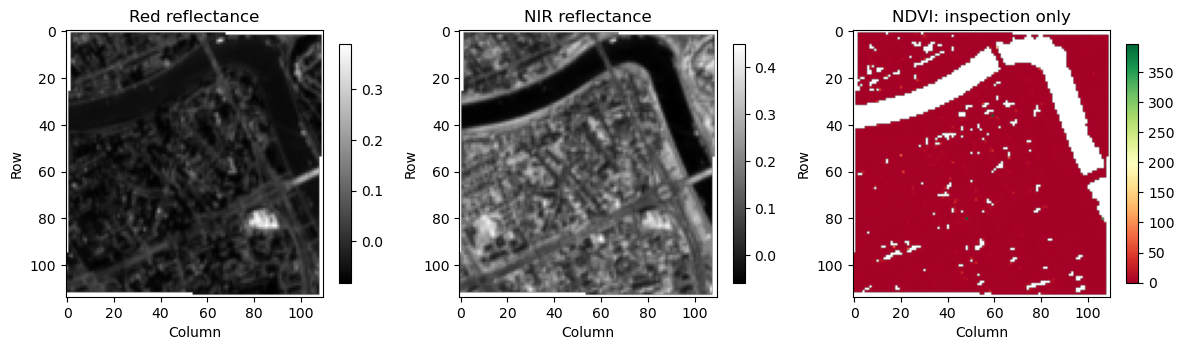

In [13]:
import numpy as np
import rasterio
import matplotlib.pyplot as plt

paths = {}
if DB.is_file():
    with sqlite3.connect(f'{DB.as_uri()}?mode=ro', uri=True) as conn:
        names = {row[0] for row in conn.execute("SELECT name FROM sqlite_master WHERE type='table'")}
        if 'artifact_locations' in names:
            for band, path in conn.execute("""SELECT a.asset_key,l.local_path FROM subset_requests s
                JOIN assets a USING(asset_id) JOIN artifact_locations l ON l.artifact_id=s.latest_artifact_id
                WHERE l.status='available' ORDER BY s.updated_at"""):
                paths[band] = Path(path)
if set(paths) != {'red','nir'} or not all(p.is_file() for p in paths.values()):
    print('Acquire both main-archive AOI subsets first; no download is performed by this cell.')
else:
    arrays = {}
    grids = {}
    for band, path in paths.items():
        with rasterio.open(path) as src:
            grids[band] = (src.crs, src.transform, src.shape)
            arrays[band] = src.read(1, masked=True).astype('float32') * src.scales[0] + src.offsets[0]
            print(band, src.shape, src.crs, 'scale:', src.scales[0], 'offset:', src.offsets[0])
    assert grids['red'] == grids['nir'], 'Choose the same AOI and aligned bands'
    red, nir = arrays['red'], arrays['nir']
    denominator = nir + red
    with np.errstate(divide='ignore', invalid='ignore'):
        ndvi = np.ma.masked_where(denominator <= 0, (nir-red) / denominator)
    fig, axes = plt.subplots(1,3,figsize=(12,4))
    for ax, values, title in zip(axes,[red,nir,ndvi],['Red reflectance','NIR reflectance','NDVI: inspection only']):
        im = ax.imshow(values, cmap='RdYlGn' if title.startswith('NDVI') else 'gray')
        ax.set_title(title); ax.set_xlabel('Column'); ax.set_ylabel('Row')
        fig.colorbar(im,ax=ax,shrink=0.65)
    plt.tight_layout()
    plt.show()


NDVI min/max: -0.20855614973262043 397.0000000000024
pixels outside [-1, 1]: 6959
masked pixels: 2484 of 12540


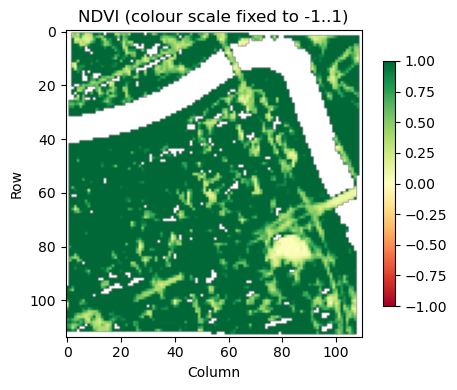

In [14]:
print('NDVI min/max:', float(ndvi.min()), float(ndvi.max()))
print('pixels outside [-1, 1]:', int(((ndvi < -1) | (ndvi > 1)).sum()))
print('masked pixels:', int(ndvi.mask.sum()), 'of', ndvi.size)

fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(ndvi, cmap='RdYlGn', vmin=-1, vmax=1)
ax.set_title('NDVI (colour scale fixed to -1..1)')
ax.set_xlabel('Column'); ax.set_ylabel('Row')
fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout(); plt.show()

In [16]:
valid = ~np.ma.getmaskarray(ndvi)
print('valid pixels:', int(valid.sum()))
print('red < 0:', int((red < 0).sum()), ' nir < 0:', int((nir < 0).sum()))
print('NDVI > 1 and red < 0:', int(((ndvi > 1) & (red < 0)).sum()))
print('NDVI percentiles 1/5/25/50/75/95/99:',
      np.round(np.percentile(ndvi.compressed(), [1, 5, 25, 50, 75, 95, 99]), 3))
print('red DN range:', float((red.min() + 0.1) / 0.0001), float((red.max() + 0.1) / 0.0001))

valid pixels: 10056
red < 0: 8838  nir < 0: 1496
NDVI > 1 and red < 0: 6959
NDVI percentiles 1/5/25/50/75/95/99: [ 0.105  0.347  0.876  1.367  1.87   3.617 10.459]
red DN range: 182.99999999999997 4888.0


### NDVI inspection (main archive)

The cell used the **alternate** AOI (shape 114 rows × 110 columns), not the default one (227 × 219): it loops over all `available` locations ordered by `updated_at` and keeps the last path per band, and the alternate AOI was acquired last. Both bands share EPSG:32634, scale 0.0001 and offset −0.1, so the grids match. Reflectance is computed as `DN × scale + offset`; the offset does not cancel in NDVI = (NIR − Red) / (NIR + Red), so using raw integers would give a different, wrong result.

The red and NIR panels show the river (dark) and built-up and vegetated areas. In the NDVI panel white pixels are masked: the river, where the denominator is ≤ 0, and the border pixels outside the AOI (nodata). The default colour scale reaches about 390, far outside the valid NDVI range of −1 to 1, so the panel is almost uniform. This is probably caused by a few pixels with a tiny positive denominator (very dark pixels, mostly water, where reflectance after the offset is close to zero). With the colour scale fixed to the default colour scale reaches 397 because the NDVI values are not confined to [−1, 1]: of 10,056 unmasked pixels, 8,838 have negative red reflectance (red DN < 1,000 after subtracting the 0.1 offset) and 6,959 have NDVI > 1, all with negative red. The median NDVI is 1.37 and the 95th percentile 3.6. This is not a handful of dark pixels; most of the image is affected. This shows why the exercise warns that calibration factors cannot simply be assumed to cancel. the contrast between vegetation and built-up areas becomes visible.

This is an inspection only: no cloud or scene classification mask was used, no quality control was done, and nothing was registered in the archive. It is not a cloud-screened NDVI product.

Corrupt

In [12]:
import sqlite3
from pathlib import Path

CORRUPT_DB = Path.cwd() / 'cases' / 'corrupt' / 'state' / 'catalogue.sqlite'
assert CORRUPT_DB.is_file(), 'Run the corrupt case first'

def show_c(title, sql):
    with sqlite3.connect(f'{CORRUPT_DB.as_uri()}?mode=ro', uri=True) as conn:
        conn.row_factory = sqlite3.Row
        rows = [dict(r) for r in conn.execute(sql)]
    print(f'\n=== {title}  ({len(rows)} rows) ===')
    for r in rows:
        print(r)
    return rows

show_c('C1 history', """
SELECT a.asset_key, d.run_id, d.started_at, d.status, d.stage, d.error_code,
       d.network_bytes, d.artifact_id
FROM download_attempts d
JOIN subset_requests s ON s.subset_id = d.subset_id
JOIN assets a ON a.asset_id = s.asset_id
ORDER BY a.asset_key, d.started_at, d.attempt_id;""")

state = show_c('C2 current state vs recorded bytes', """
SELECT a.asset_key, s.status AS request_status, f.size_bytes, f.sha256,
       l.local_path, l.status AS location_status, l.checked_at
FROM subset_requests s
JOIN assets a ON a.asset_id = s.asset_id
JOIN artifacts f ON f.artifact_id = s.latest_artifact_id
LEFT JOIN artifact_locations l ON l.artifact_id = f.artifact_id
ORDER BY a.asset_key;""")

print('\n=== Filesystem vs. database ===')
for r in state:
    p = Path(r['local_path'])
    print(r['asset_key'], 'exists:', p.is_file(),
          'on-disk bytes:', p.stat().st_size if p.is_file() else None,
          'recorded bytes:', r['size_bytes'])


=== C1 history  (7 rows) ===
{'asset_key': 'nir', 'run_id': 'lab03-d16b3088-3b97-4aa1-8f7d-4899ca6c1846', 'started_at': '2026-11-01T22:36:37.258474Z', 'status': 'succeeded', 'stage': 'complete', 'error_code': None, 'network_bytes': 2097153, 'artifact_id': 'fca9fc0ea7e68ceff3015929352513dbcdd0d9a9d9e5d75cb90ca393bc502adb'}
{'asset_key': 'nir', 'run_id': 'lab03-df7d0c50-9a81-4ed4-9037-210225eb6b38', 'started_at': '2026-11-01T22:36:42.684507Z', 'status': 'reused', 'stage': 'cache_verify', 'error_code': None, 'network_bytes': 0, 'artifact_id': 'fca9fc0ea7e68ceff3015929352513dbcdd0d9a9d9e5d75cb90ca393bc502adb'}
{'asset_key': 'nir', 'run_id': 'lab03-a8c8ea8e-f517-42f0-ac8f-445f9bebf3a2', 'started_at': '2026-11-01T22:40:00.021891Z', 'status': 'reused', 'stage': 'cache_verify', 'error_code': None, 'network_bytes': 0, 'artifact_id': 'fca9fc0ea7e68ceff3015929352513dbcdd0d9a9d9e5d75cb90ca393bc502adb'}
{'asset_key': 'red', 'run_id': 'lab03-d16b3088-3b97-4aa1-8f7d-4899ca6c1846', 'started_at': '202

### Case `corrupt` evidence (before recovery)

**Prediction check.** All points held. In run 2 (`verify`, `lab03-df7d0c50…`), `red` got a `failed` attempt at stage `cache_verify` with `FILE_CORRUPT` and 0 network bytes, while `nir` was `reused`. The `red` location status is `corrupt`, the `red` request is `failed`, and the run failed (exit code 1). The original `succeeded` attempt of run 1 is unchanged.

**Database vs. filesystem.** The file still exists but has 37,896 bytes on disk against 75,792 recorded in `artifacts` (exactly half, as `damage` truncates to `size // 2`). `artifacts.sha256` (`df429fb5…`) and `size_bytes` were not changed: they describe the bytes that were stored, not the damaged file.

**FILE_CORRUPT vs. FILE_MISSING.** Both are detected by a later `cache_verify` attempt and leave the first success in the history. With `FILE_MISSING` the path does not exist and location status is `missing`; here the path exists and the status is `corrupt`, because the size (and, if the size matched, the SHA-256) differs from the recorded values. An existence check alone would have called this file fine. The code compares size before the hash, so the size mismatch is enough to fail, and no database constraint can detect either situation: only reading the file can.

### Case `corrupt` recovery

`python lab03_cli.py acquire --config cases/corrupt/config.json` (run 3, `lab03-a8c8ea8e…`, `succeeded`). The log shows a second `FILE_CORRUPT` verification attempt for `red` (the location row was still `corrupt`), followed by a new `read_window` attempt that succeeded (2,097,153 network bytes, 75,792 bytes saved). `nir` was `reused` with 0 bytes. The artifact id of `red` is unchanged (`59d7497b…`) and the new file was written under the same name, replacing the truncated one. Post-recovery evidence (queries C1/C2): `red` has four attempts in total (run 1 `succeeded`, run 2 `FILE_CORRUPT`, run 3 `FILE_CORRUPT` and then a new `succeeded`), `nir` has three (`succeeded`, `reused`, `reused`). Both requests are `ready` and both locations `available`. The `red` file on disk again has 75,792 bytes, equal to `artifacts.size_bytes`, and its SHA-256 is still `df429fb5…`, so the artifact id is unchanged: the re-downloaded bytes are identical and the damaged file was replaced under the same name. The failed attempts remain in the history.

## Submission and interpretation

Submit student_schema.sql, your investigation_queries.sql, this notebook with
predictions/SQL results/explanations, and a small report:

```bash
python lab03_cli.py report --config config/krakow_aoi.json > lab03_report.json
```

For each required failure, state: symptom, query, observed rows, diagnosis, recovery,
and post-recovery evidence. A screenshot alone is not a diagnosis. Explain which
claims are protected by database constraints and which require checking bytes,
filesystem state or raster metadata.

Keep state/, data/, and cases/ out of Git. Successful offline checks do not claim
that a live request succeeded. If the provider/network is unavailable, retain that
failure evidence and complete the live acquisition later; no synthetic image is
substituted.

Sources: [Rasterio windowed reading/writing](https://rasterio.readthedocs.io/en/latest/topics/windowed-rw.html)
and [Earth Search metadata](https://github.com/Element84/earth-search/blob/main/README.md).
